In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df=pd.read_csv('data.csv')
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [80]:
def sigmoid(z):
    return 1/(1+np.exp(-z))

In [81]:
def compute_cost(x_train,y_train,w,b):
    m=len(x_train)
    z=np.dot(x_train,w)+b
    f=sigmoid(z)
    f = np.clip(f, 1e-15, 1 - 1e-15) #to avoid log(0) case
    cost=np.sum(y_train*np.log(f)+(1-y_train)*np.log(1-f))/(-m)

    return cost

In [82]:
def compute_gradient(x,y,w,b):
    m=len(x)
    z=np.dot(x,w)+b
    f=sigmoid(z)
    error=f-y
    dj_dw=np.dot(x.T,error)/m
    dj_db=np.sum(error)/m

    return dj_dw,dj_db
    

In [83]:
def gradient_descent(x,y,w,b,alpha,epoch):
    cost_history=[]

    for i in range(epoch):
        dj_dw,dj_db=compute_gradient(x,y,w,b)
        w=w-alpha*dj_dw
        b=b-alpha*dj_db
        
        cost=compute_cost(x,y,w,b)
        cost_history.append(cost)
    
    return w,b,cost_history

In [84]:
#mapping and dropping unnessesary columns
df.drop(columns=['id','Unnamed: 32'],inplace=True)
print(df.isnull().sum())
df['diagnosis']=df['diagnosis'].map({ 'M':1,'B':0})
x_train=df.drop(columns=['diagnosis'])
y_train=df['diagnosis']

#using feature scaling
mean=np.mean(x_train,axis=0)
std=np.std(x_train,axis=0)
x_norm=(x_train-mean)/std

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64


In [85]:
X=x_norm.to_numpy()
Y=y_train.to_numpy()

m,n=np.shape(X)
w=np.zeros(n)
b=0
alpha=0.01
epoch=2000
w,b,cost_history=gradient_descent(X,Y,w,b,alpha,epoch)

z=np.dot(X,w)+b
Y_prob=sigmoid(z)
Y_pred = (Y_prob >= 0.5).astype(int)

In [86]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

print("Accuracy:", accuracy_score(Y,Y_pred))
print(confusion_matrix(Y,Y_pred))

Accuracy: 0.984182776801406
[[355   2]
 [  7 205]]


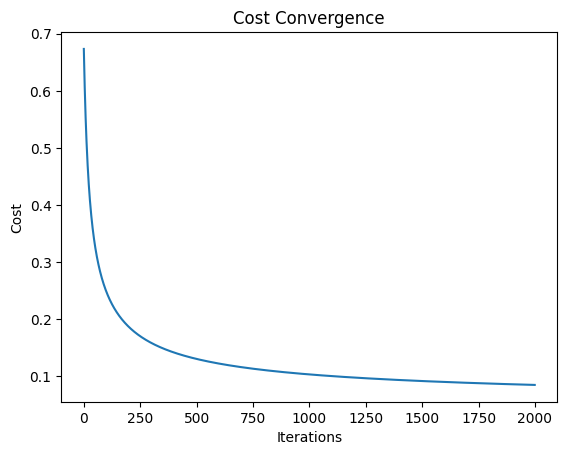

In [87]:
plt.plot(cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Convergence")
plt.show()